# 05 | Feature analysis and handoff

Audit every feature table, inspect distributions on a training trip, and demonstrate a safe offline label join. No classifier is trained here.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/data/dataset_loader.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the PathSnap repository or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW = Path(os.environ.get("PATHSNAP_RAW_ROOT", str(ROOT / "data/raw")))
EVIDENCE = ROOT / "results/member1"
if not (EVIDENCE / "processing_summary.csv").exists():
    raise RuntimeError("Run python -m src.data.prepare_member1 first")
inventory = pd.read_csv(EVIDENCE / "dataset_inventory.csv", dtype={"trip_id": str})
summary = pd.read_csv(EVIDENCE / "processing_summary.csv", dtype={"trip_id": str})
display(inventory.groupby("partition").agg(trips=("trip_id", "size"), gps=("gps_observations", "sum")))

,trips,gps
partition,,
student_test,10,19160
train,80,208417


In [2]:
from src.features.feature_extractor import FEATURE_COLUMNS, IDENTIFIER_COLUMNS
from src.features.reference_labeling import build_training_table
audit = []
for row in summary.itertuples(index=False):
    path = ROOT / "data/features" / row.partition / f"{row.trip_id}.csv.gz"
    frame = pd.read_csv(path, dtype={"trip_id": str})
    assert frame.columns.tolist() == IDENTIFIER_COLUMNS + FEATURE_COLUMNS
    assert np.isfinite(frame[FEATURE_COLUMNS].to_numpy()).all()
    assert not frame.duplicated(["observation_id", "candidate_arc_id"]).any()
    assert frame.trip_id.eq(row.trip_id).all()
    audit.append({"partition": row.partition, "trip_id": row.trip_id, "feature_rows": len(frame), "feature_count": len(FEATURE_COLUMNS)})
display(pd.DataFrame(audit).groupby("partition").agg(trips=("trip_id", "size"), rows=("feature_rows", "sum")))
print("All saved feature tables passed schema, finiteness and key checks.")

,trips,rows
partition,,
student_test,10,113648
train,80,1124837


All saved feature tables passed schema, finiteness and key checks.


distance_m                  heading_difference_deg                    \
             mean     median count                   mean      median count   
target                                                                        
0       24.397702  23.229188  5970              98.626271  113.377972  5970   
1        4.911884   4.098907  1103               8.543838    5.658974  1103   

       candidate_rank               
                 mean median count  
target                              
0            4.604858    4.0  5970  
1            1.249320    1.0  1103

,observations
label_status,
usable_proxy,1104
ambiguous_alignment,210
speed_outlier,1


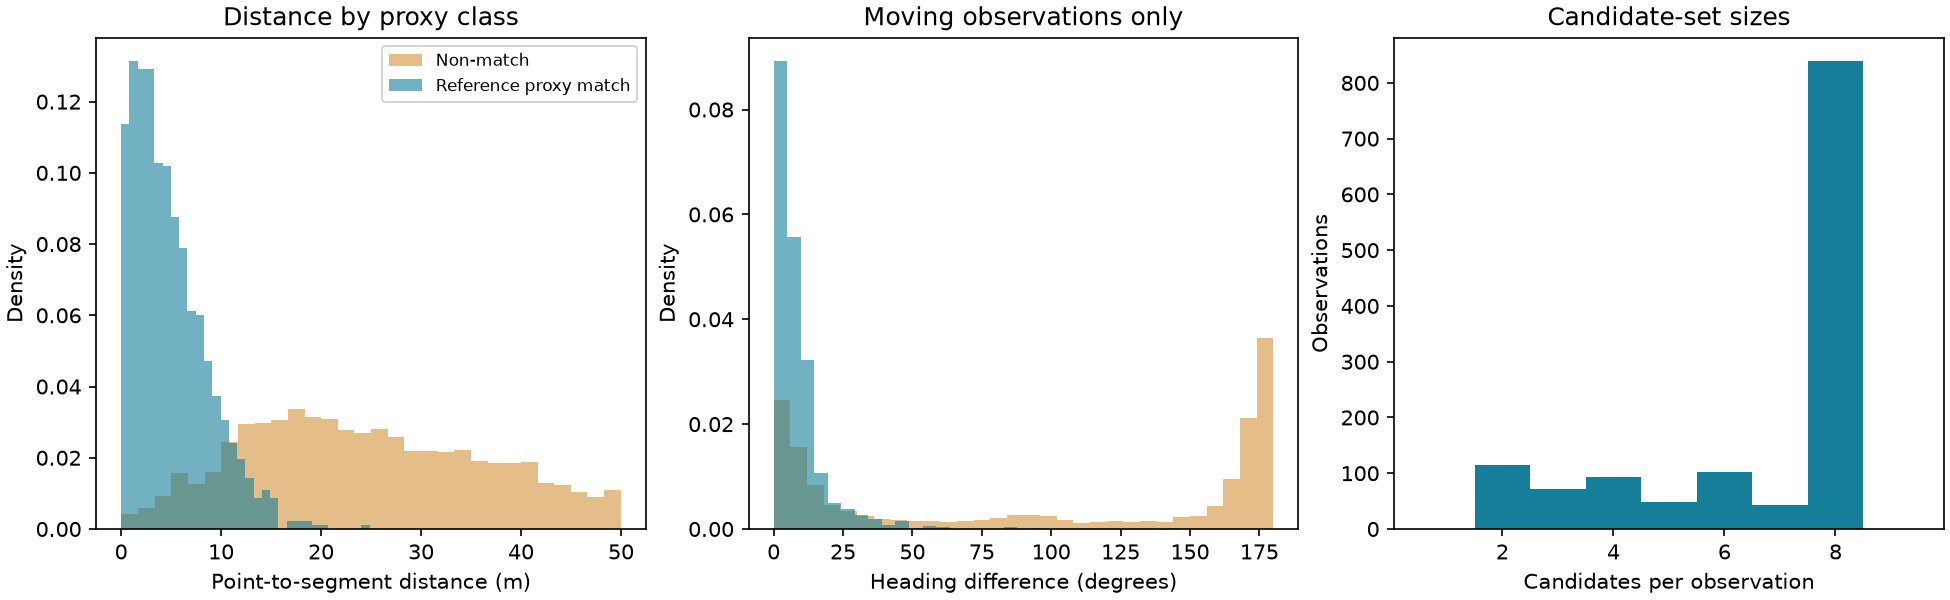

Handoff shapes: (7073, 23) (7073,) Group key is trip_id.


In [3]:
row = summary.loc[summary.partition == "train"].iloc[0]
features = pd.read_csv(ROOT / "data/features" / row.partition / f"{row.trip_id}.csv.gz", dtype={"trip_id": str})
labels = pd.read_csv(ROOT / "data/processed" / row.partition / row.trip_id / "reference_labels.csv.gz")
joined = build_training_table(features, labels)
eligible = joined.loc[joined.training_eligible]
display(eligible.groupby("target")[["distance_m", "heading_difference_deg", "candidate_rank"]].agg(["mean", "median", "count"]))
display(labels.label_status.value_counts().to_frame("observations"))
display(Image(filename=str(EVIDENCE / f"train_{row.trip_id}_features.png")))
X = eligible[FEATURE_COLUMNS]
y = eligible.target.astype(int)
groups = eligible.trip_id
assert "reference_arc_id" not in X.columns
print("Handoff shapes:", X.shape, y.shape, "Group key is trip_id.")

## Interpretation
Feature differences by proxy class are descriptive and do not establish generalization performance. Binary candidate targets are imbalanced; classification accuracy alone may be misleading. Preserve candidate-to-arc correspondence, fit scaling only inside grouped training folds, retain student-test separation, and never select IDs/reference fields as features. Feature definitions and alignment limitations are in `docs/feature_specification.md`.